#Multiclass, Multilabel and Boosting Classification
In this lab session, we first focus on performing *multiclass* classification. We practice using various classification techniques, as well as some boosting algorithms.

Later, we see how we can extend what we have learned to multilabel problems.

#About the Dataset
The dataset we work with in this lab session is about predicting the position of football players in FIFA 2019 game. The data is [hosted on Kaggle](https://www.kaggle.com/karangadiya/fifa19) and contains 88 features for 18207 players.

Our task would be to predict where in the field each player plays, hence dealing with a multiclass prediction problem.


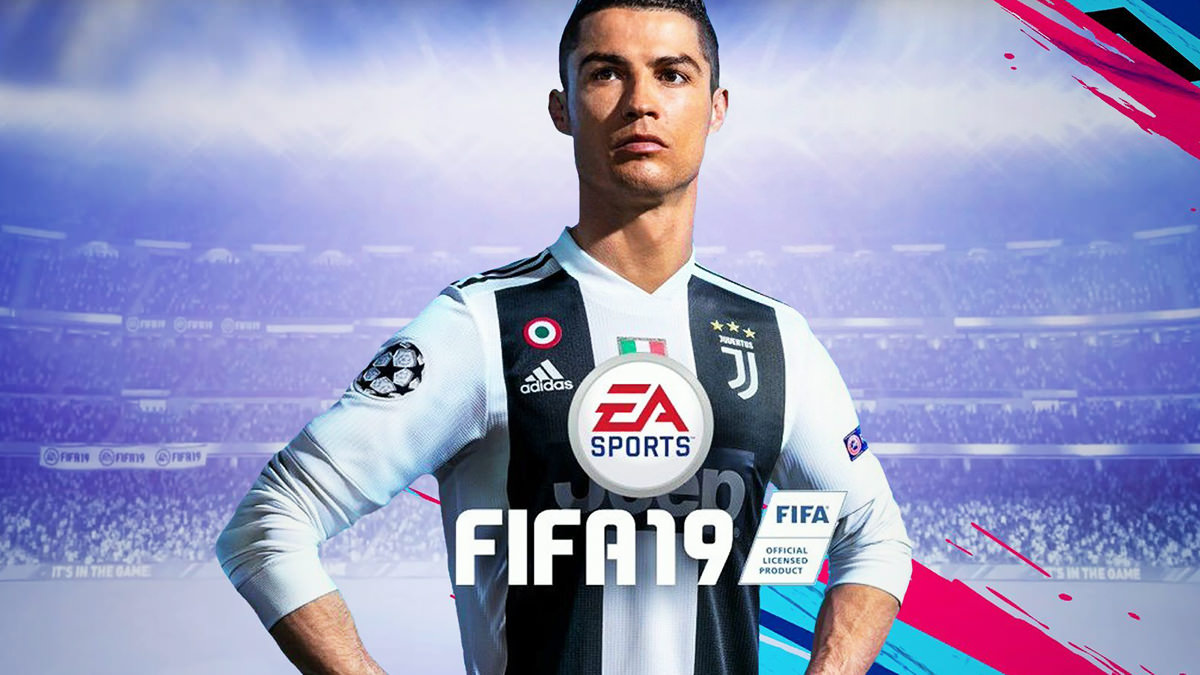

# Installing and Importing Libraries
For the examples we will work on in this notebook, we first need to upgrade the scikit-learn libraries.

Please note that **we will need to restart runtime** after executing the following block.

In [1]:
# First, let's upgrade scikit-learn package in colab
# !pip uninstall scikit-learn -y
# !pip install -U scikit-learn
import sklearn
print(sklearn.__version__)

Found existing installation: scikit-learn 1.5.2
Uninstalling scikit-learn-1.5.2:
  Successfully uninstalled scikit-learn-1.5.2
  Using cached scikit_learn-1.5.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (13 kB)
Using cached scikit_learn-1.5.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (13.3 MB)
1.5.2


Now let's import the libraries we will need later on.

In [2]:
import pandas as pd
import io
import os
import numpy as np
import copy
import seaborn as sns #visualisation
import matplotlib.pyplot as plt #visualisation
%matplotlib inline
sns.set(color_codes=True)

# Loading the Dataset
Given the size, we load the data directly from Kaggle this time.

In [3]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [4]:
os.environ['KAGGLE_CONFIG_DIR'] = "/content/gdrive/My Drive/Kaggle"

In [5]:
! kaggle datasets download -d sujaypandit/fifa19-player-and-league-dataset

Dataset URL: https://www.kaggle.com/datasets/sujaypandit/fifa19-player-and-league-dataset
License(s): CC-BY-NC-SA-4.0
  0% 0.00/1.94M [00:00<?, ?B/s]
100% 1.94M/1.94M [00:00<00:00, 140MB/s]


In [6]:
# !unzip \*.zip && rm *.zip -y

Archive:  fifa19-player-and-league-dataset.zip
replace Fifa19.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: Fifa19.csv              
rm: invalid option -- 'y'
Try 'rm --help' for more information.


Next step would be to load the CSV file into a Pandas dataframe.

In [7]:
df = pd.read_csv('Fifa19.csv')
print(df.shape)

(16344, 89)


Now let's take a look at the first few rows of the data:

In [8]:
df.head(10)

,Club,Playing_in_League,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,Real Madrid,Spain Primera Division (1),177003,L. Modrić,32,https://cdn.sofifa.org/players/4/19/177003.png,Croatia,https://cdn.sofifa.org/flags/10.png,91,91,...,84.0,60.0,76.0,73.0,13.0,9.0,7.0,14.0,9.0,€137.4M
1,Real Madrid,Spain Primera Division (1),155862,Sergio Ramos,32,https://cdn.sofifa.org/players/4/19/155862.png,Spain,https://cdn.sofifa.org/flags/45.png,91,91,...,82.0,87.0,92.0,91.0,11.0,8.0,9.0,7.0,11.0,€104.6M
2,Real Madrid,Spain Primera Division (1),182521,T. Kroos,28,https://cdn.sofifa.org/players/4/19/182521.png,Germany,https://cdn.sofifa.org/flags/21.png,90,90,...,85.0,72.0,79.0,69.0,10.0,11.0,13.0,7.0,10.0,€156.8M
3,Real Madrid,Spain Primera Division (1),192119,T. Courtois,26,https://cdn.sofifa.org/players/4/19/192119.png,Belgium,https://cdn.sofifa.org/flags/7.png,89,90,...,66.0,20.0,18.0,16.0,85.0,91.0,72.0,86.0,88.0,€113.7M
4,Real Madrid,Spain Primera Division (1),200145,Casemiro,26,https://cdn.sofifa.org/players/4/19/200145.png,Brazil,https://cdn.sofifa.org/flags/54.png,88,90,...,84.0,88.0,90.0,87.0,13.0,14.0,16.0,12.0,12.0,€126.4M
5,Real Madrid,Spain Primera Division (1),197781,Isco,26,https://cdn.sofifa.org/players/4/19/197781.png,Spain,https://cdn.sofifa.org/flags/45.png,88,91,...,86.0,60.0,64.0,51.0,10.0,8.0,12.0,15.0,6.0,€156.2M
6,Real Madrid,Spain Primera Division (1),176676,Marcelo,30,https://cdn.sofifa.org/players/4/19/176676.png,Brazil,https://cdn.sofifa.org/flags/54.png,88,88,...,86.0,71.0,85.0,86.0,12.0,5.0,5.0,5.0,9.0,€88.2M
7,Real Madrid,Spain Primera Division (1),173731,G. Bale,28,https://cdn.sofifa.org/players/4/19/173731.png,Wales,https://cdn.sofifa.org/flags/50.png,88,88,...,86.0,54.0,55.0,52.0,15.0,15.0,11.0,5.0,6.0,€123M
8,Real Madrid,Spain Primera Division (1),193041,K. Navas,31,https://cdn.sofifa.org/players/4/19/193041.png,Costa Rica,https://cdn.sofifa.org/flags/72.png,87,87,...,67.0,28.0,14.0,14.0,90.0,81.0,75.0,82.0,90.0,€62.5M
9,Real Madrid,Spain Primera Division (1),201535,R. Varane,25,https://cdn.sofifa.org/players/4/19/201535.png,France,https://cdn.sofifa.org/flags/18.png,86,91,...,82.0,87.0,88.0,87.0,11.0,11.0,9.0,5.0,14.0,€106.3M


And here's a summary of the dataset as a whole.
It shows us the columns, their datatype, and how many values in that column are null (empty/missing data). Thankfully, we don't have any missing values!

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16344 entries, 0 to 16343
Data columns (total 89 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Club                      16344 non-null  object 
 1   Playing_in_League         16344 non-null  object 
 2   ID                        16344 non-null  int64  
 3   Name                      16344 non-null  object 
 4   Age                       16344 non-null  int64  
 5   Photo                     16344 non-null  object 
 6   Nationality               16344 non-null  object 
 7   Flag                      16344 non-null  object 
 8   Overall                   16344 non-null  int64  
 9   Potential                 16344 non-null  int64  
 10  Club Logo                 16344 non-null  object 
 11  Value                     16344 non-null  object 
 12  Wage                      16344 non-null  object 
 13  Special                   16344 non-null  int64  
 14  Prefer

# Getting Some Insights from Our Data
It is now time to do some EDA! We just play with different data columns to get more sense about our data.

First, let's check the distribution of palyers age

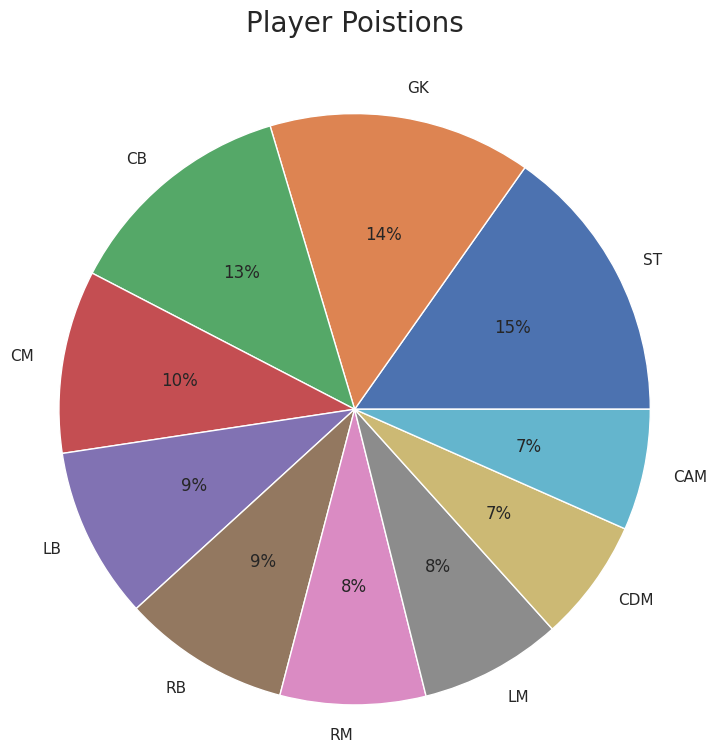

In [10]:
df['Position'].value_counts()[0:10].plot.pie(autopct='%1.0f%%',radius=2,ylabel='')
plt.title('Player Poistions', y=1.5,fontsize=20)
plt.show()

In [11]:
print('Total number of unique positions: %d' %len(df['Position'].unique()))

Total number of unique positions: 28


In [12]:
df['Position'].unique()

array(['RCM', 'RCB', 'LCM', 'GK', 'CDM', 'LW', 'LB', 'ST', 'RW', 'RB',
       'CB', 'CM', 'RDM', 'RM', 'CAM', 'LM', 'LCB', 'RF', 'RS', 'LDM',
       'LF', 'RAM', 'LS', 'LAM', 'CF', 'RWB', nan, 'LWB'], dtype=object)

It seems we have too many positions! We can combine some of them together to simplify the problem:

In [13]:
# We go for a 4-3-3 formation!
df.loc[df['Position']=='ST','Position']='CF'              # All strickers are now counte as Central Forward (CF)
df.loc[df['Position'].isin(['RS' , 'RWF, RW']),'Position']='RF'              # All right strikers are counted as Right Forward (RF)
df.loc[df['Position'].isin(['LS' , 'LWF, LW']),'Position']='LF'              # All left strikers are counted as Left Forward (RF)

# Midfield
df.loc[df['Position'].isin(['RCM','RAM','RDM']),'Position']='RM'      # All variants right Middfieldsers (i.e. attacking and defending) are now counted as right middfielders
df.loc[df['Position'].isin(['LCM','LAM','LDM']),'Position']='LM'      # All variants left Middfieldsers (i.e. attacking and defending) are now counted as left middfielders
df.loc[df['Position'].isin(['CAM','CDM']),'Position']='CM'              # All central midfielders grouped together

# Defense
df.loc[df['Position'].isin(['RWB']),'Position']='RB'      # All variants right defenders (i.e. wing and wing back) are now counted as right defenders
df.loc[df['Position'].isin(['LWB']),'Position']='LB'      # All variants Left defenders (i.e. wing and wing back) are now counted as left defenders
df.loc[df['Position'].isin(['RCB','LCB']),'Position']='CB'      # All variants Left defenders (i.e. wing and wing back) are now counted as left defenders

In [14]:
print('Total number of unique positions: %d' %len(df['Position'].unique()))

Total number of unique positions: 13


In [15]:
df['Position'].unique()

array(['RM', 'CB', 'LM', 'GK', 'CM', 'LW', 'LB', 'CF', 'RW', 'RB', 'RF',
       'LF', nan], dtype=object)

# Data Cleaning
From the above overview, we saw some rows with null values. To save time, we simply drop them here.

In [16]:
for col_name in list(df.columns):
  no_null_values = sum(df[col_name].isnull())
  if no_null_values:
    print('Number of null values in column %s is %d' %(col_name,no_null_values))

Number of null values in column Preferred Foot is 40
Number of null values in column International Reputation is 40
Number of null values in column Weak Foot is 40
Number of null values in column Skill Moves is 40
Number of null values in column Work Rate is 40
Number of null values in column Body Type is 40
Number of null values in column Real Face is 40
Number of null values in column Position is 40
Number of null values in column Jersey Number is 40
Number of null values in column Joined is 1174
Number of null values in column Loaned From is 15210
Number of null values in column Contract Valid Until is 40
Number of null values in column Height is 40
Number of null values in column Weight is 40
Number of null values in column LS is 1859
Number of null values in column ST is 1859
Number of null values in column RS is 1859
Number of null values in column LW is 1859
Number of null values in column LF is 1859
Number of null values in column CF is 1859
Number of null values in column RF i

In [17]:
# First, drop the columns with many null values
df.drop(['Loaned From'], axis=1, inplace=True)

In [18]:
df.dropna(inplace=True)

In [19]:
df.shape

(13425, 88)

# Feature Engineering
It would be nice to do some feature engineering before moving to the regression phase.

However, in the interest of time, and since we seem to have sufficient columns, we bypass this step.

# Data Preprocessing
Next step in preparing our data would be to make all columns have numerical values.


In [20]:
df.select_dtypes(include = "object").columns

Index(['Club', 'Playing_in_League', 'Name', 'Photo', 'Nationality', 'Flag',
       'Club Logo', 'Value', 'Wage', 'Preferred Foot', 'Work Rate',
       'Body Type', 'Real Face', 'Position', 'Joined', 'Contract Valid Until',
       'Height', 'Weight', 'LS', 'ST', 'RS', 'LW', 'LF', 'CF', 'RF', 'RW',
       'LAM', 'CAM', 'RAM', 'LM', 'LCM', 'CM', 'RCM', 'RM', 'LWB', 'LDM',
       'CDM', 'RDM', 'RWB', 'LB', 'LCB', 'CB', 'RCB', 'RB', 'Release Clause'],
      dtype='object')

First, let's convert the skill scores to numbers

In [21]:
df['LS'].head()

,LS
0,77+3
1,73+3
2,78+3
4,72+3
5,76+3


In [22]:
skills_columns = ['LS','ST','RS','LW','LF','CF','RF','RW','LAM','CAM','RAM',
                  'LM','LCM','CM','RCM','RM','LWB','LDM','CDM','RDM','RWB',
                  'LB','LCB','CB','RCB','RB']
for col_name in skills_columns:
  df[col_name] = df[col_name].str.split('+').str[0]
  df[col_name] = df[col_name].astype(int)

Now let's drop unnecessary columns:

In [23]:
df_orig = copy.deepcopy(df)
to_drop_columns = ['Name','Photo','Playing_in_League','Nationality','Flag','Club','Club Logo','Real Face','Joined','Contract Valid Until']
df.drop(to_drop_columns, axis=1, inplace=True)

The "Value" column has also currency signs and the numbers are in the form of#

*   €110.5M,
*   €77M
*   €118.5M
*   ...
we define a function and apply it to the column to make it numerical.
  



In [24]:
  def convert_currency_to_number(x):
      output = x.replace('€','')
      if 'M' in x:
        output = output.replace('M','')
        output = float(output) * 1e6
      elif 'K' in x:
        output = output.replace('K','')
        output = float(output) * 1e3
      output = float(output)
      return output

In [25]:
df['Value'] = df['Value'].apply(convert_currency_to_number)
df['Wage'] = df['Wage'].apply(convert_currency_to_number)
df['Release Clause'] = df['Release Clause'].apply(convert_currency_to_number)

We face a similar situation for height and weight

In [26]:
  def convert_height_to_number(x):
      output = x.replace("'",'.')
      return float(output)* 30.48

In [27]:
df['Height'] = df['Height'].apply(convert_height_to_number)

In [28]:
  def convert_weight_to_number(x):
      output = x.replace("lbs",'')
      return float(output)* .4205

In [29]:
df['Weight'] = df['Weight'].apply(convert_weight_to_number)

Now let's see what other columns we have with non-numeric values

In [30]:
for col_name in list(df.select_dtypes(include = "object").columns):
  print('Number of unique values in column %s is %d\n' %(col_name,len(df[col_name].unique())))

Number of unique values in column Preferred Foot is 2

Number of unique values in column Work Rate is 9

Number of unique values in column Body Type is 9

Number of unique values in column Position is 11



Given that the range of unique values for each column is not that large, let's use one-hot encoding.


In [31]:
target_positions = df.pop('Position')
to_one_hot_columns = list(df.select_dtypes(include = "object").columns)
print(to_one_hot_columns)
onehot_column_names = []
for column in to_one_hot_columns:
    encoded_df = pd.get_dummies(df[column])
    df[encoded_df.columns] = encoded_df     # Insert the newly encoded columns into the dataset
    onehot_column_names += list(encoded_df.columns)
df.head()

['Preferred Foot', 'Work Rate', 'Body Type']


,ID,Age,Overall,Potential,Value,Wage,Special,Preferred Foot,International Reputation,Weak Foot,...,Medium/ Medium,Akinfenwa,C. Ronaldo,Lean,Messi,Neymar,Normal,PLAYER_BODY_TYPE_25,Shaqiri,Stocky
0,177003,32,91,91,67000000.0,420000.0,2280,Right,4.0,4.0,...,False,False,False,True,False,False,False,False,False,False
1,155862,32,91,91,51000000.0,380000.0,2201,Right,4.0,3.0,...,False,False,False,False,False,False,True,False,False,False
2,182521,28,90,90,76500000.0,355000.0,2190,Right,4.0,5.0,...,True,False,False,False,False,False,True,False,False,False
4,200145,26,88,90,59500000.0,285000.0,2170,Right,3.0,3.0,...,False,False,False,False,False,False,True,False,False,False
5,197781,26,88,91,73500000.0,315000.0,2137,Right,3.0,3.0,...,False,False,False,False,False,False,True,False,False,False


The "Body Type" column has some very weird values in it!!

In [32]:
df['Body Type'].unique()

array(['Lean', 'Normal', 'Stocky', 'PLAYER_BODY_TYPE_25', 'Shaqiri',
       'Messi', 'C. Ronaldo', 'Neymar', 'Akinfenwa'], dtype=object)

In [33]:
# Let's drop non-numeric columns
df.drop(to_one_hot_columns, axis=1, inplace=True)

In [34]:
# Let's remove white spaces fro column names, as this will cause some errors in plotting the decision trees later on
df.rename(columns = lambda x: x.replace(' ', '_'), inplace=True)

### Normalization/Stadardization
Our next step would be to "normalize" all the columns so thatthey have a "similar" range. To this end, we will use scikit-learn's SatndardScaler, to make the selected columns have the normal distribution.

In [35]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

standard_scaling_columns = list(set(df.columns) - set(onehot_column_names))
df[standard_scaling_columns] = scaler.fit_transform(df[standard_scaling_columns])
df[standard_scaling_columns].describe()

,Curve,Value,LF,Low/_Low,RF,Medium/_Low,Crossing,CAM,StandingTackle,RB,...,C._Ronaldo,LCM,High/_High,RCM,CB,GKDiving,BallControl,ShotPower,LB,GKReflexes
count,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,...,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04,1.342500e+04
mean,-6.774635e-17,-5.080976e-17,1.354927e-16,-2.117073e-18,1.354927e-16,5.557317e-17,-3.387317e-17,2.371122e-16,2.540488e-17,-2.709854e-16,...,3.175610e-18,2.371122e-16,-1.270244e-17,2.371122e-16,-2.286439e-16,-1.058537e-16,-1.354927e-16,1.693659e-16,-2.709854e-16,-1.508415e-16
std,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,...,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00,1.000037e+00
min,-2.668574e+00,-4.451327e-01,-3.214914e+00,-4.489127e-02,-3.214914e+00,-2.325911e-01,-3.064366e+00,-3.263364e+00,-2.219913e+00,-2.822341e+00,...,-8.630958e-03,-3.187637e+00,-2.674212e-01,-3.187637e+00,-2.627939e+00,-3.061359e+00,-3.807261e+00,-3.382653e+00,-2.822341e+00,-3.058377e+00
25%,-7.594796e-01,-3.890730e-01,-5.875557e-01,-4.489127e-02,-5.875557e-01,-2.325911e-01,-6.662212e-01,-6.193831e-01,-8.593292e-01,-7.386738e-01,...,-8.630958e-03,-6.060188e-01,-2.674212e-01,-6.060188e-01,-8.444011e-01,-8.060717e-01,-5.305464e-01,-6.646214e-01,-7.386738e-01,-8.051098e-01
50%,3.049059e-02,-3.231205e-01,1.198099e-01,-4.489127e-02,1.198099e-01,-2.325911e-01,1.801826e-01,9.245790e-02,3.442641e-01,9.479330e-02,...,-8.630958e-03,6.744690e-02,-2.674212e-01,6.744690e-02,1.747637e-01,-1.617039e-01,6.521996e-02,9.038735e-02,9.479330e-02,-1.613193e-01
75%,8.204608e-01,-5.106635e-02,7.261233e-01,-4.489127e-02,7.261233e-01,-2.325911e-01,7.444519e-01,7.026073e-01,7.629053e-01,7.198936e-01,...,-8.630958e-03,6.286683e-01,-2.674212e-01,6.286683e-01,7.692765e-01,8.048477e-01,6.609863e-01,7.698952e-01,7.198936e-01,8.043665e-01
max,2.795386e+00,1.909165e+01,3.454533e+00,2.227605e+01,3.454533e+00,4.299391e+00,2.719394e+00,3.448280e+00,2.123489e+00,2.803561e+00,...,1.158620e+02,3.322531e+00,3.739420e+00,3.322531e+00,2.637745e+00,8.537261e+00,3.242640e+00,2.657417e+00,2.803561e+00,8.529853e+00


**Important Note**: In practice, it is better to perform normalization *after* we have separated data into train and test, and use only the train set for deriving normalization coefficient. The reason is that we supposedly do not have access to the test data.

# Pareparing Train and Test Sets
Let's break our data into train and test sets to better evaluate the performance of our algorithm.

In [36]:
# First, let's separate the target column, price
y = target_positions

In [37]:
y

,Position
0,RM
1,CB
2,LM
4,CM
5,LW
...,...
16337,LM
16338,CB
16340,CF
16341,CB


In [38]:
from sklearn.model_selection import train_test_split, cross_val_score

X_train, X_test, y_train, y_test = train_test_split(df,y,test_size=0.2)
print(X_train.shape)
print(X_test.shape)

(10740, 94)
(2685, 94)


# Classification
Now it is time to test classification algorithms in action, starting from linear classifiers.

# Boosting

### XGBoost
[XGBoost](https://xgboost.readthedocs.io/) is one of the most popular and powerful boosting algorithms available. It constructs multiple trees and combine their results to improve the performance of the whole algorithm. It also has options to speed up the whole process by using GPUs and parallilizing the tree construction.

However, using it in action is not any more difficult than using other classification algorithms we have seen so far.

But first, we need to do categorical encoding for labels (this is required for newer versions of XGBoos)

In [39]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit(y_train)
y_train = le.transform(y_train)
y_test = le.transform(y_test)

In [40]:
from xgboost import XGBClassifier
model = XGBClassifier(n_estimators=150)
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)

In [41]:
from sklearn.metrics import f1_score

y_pred = model.predict(X_test)
f1 = f1_score(y_test, y_pred, average='weighted')  # Use 'weighted' for multi-class since our dataset is imbalanced
print(f"F1 Score: {f1}")

F1 Score: 0.6211636572568807
